# Do the stage two regressors predict more conversion than the cell has wetland?

Four stage two runs, all `CellMultiLayerPerceptronLogShare` with `log1p(n_wetland)` as an input scalar:

| group | run | cell size | target |
|---|---|---|---|
| A | `results/hurdle_reg_mlp_3km_log_area` | 3 km | log percent of cell footprint converted |
| B | `results/hurdle_reg_mlp_3km_log_share` | 3 km | log share of 2019 wetland converted |
| C | `results/hurdle_reg_mlp_300m_log_area` | 300 m | log percent of cell footprint converted |
| D | `results/hurdle_reg_mlp_300m_log_share` | 300 m | log share of 2019 wetland converted |

Cells: 3 km runs use `data/cells_2019_2024_3km` (built 2026-11-03, commit 52ebf471), 300 m runs use `data/cells_2019_2024_300m` (built 2026-10-27, commit 661cfd1c). Both match the `cells` block in each run manifest, so joining on `cell_idx` is safe.

Every prediction gets turned into predicted converted pixels and compared to `n_wetland`:

* share: `pred_px = exp(pred) * n_wetland`
* area: `pred_px = exp(pred) / 100 * footprint_px`

Over the cap means `pred_px > n_wetland`, which is the same as share over 100%, or area over `100 n_wetland / footprint_px`.

Two estimates are checked. `exp(pred)` is the raw model output (a median estimate). `exp(pred) * smear` multiplies by each fold's Duan smearing factor (fit on that fold's train cells) and is what the scoring uses as the mean estimate. The training script clips the smeared prediction at the cap before scoring, so none of this shows up in the saved metrics. What we're checking here is the unclipped output.

Two populations: `val_preds` are the val cells with any conversion (what stage two is trained and scored on), `val_all_preds` are every val cell, including the ones with zero conversion, which is what the hurdle product gets applied to. Folds are pooled, so each cell appears once.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path("..")
RUNS = {
    "A": "hurdle_reg_mlp_3km_log_area",
    "B": "hurdle_reg_mlp_3km_log_share",
    "C": "hurdle_reg_mlp_300m_log_area",
    "D": "hurdle_reg_mlp_300m_log_share",
}
SPLITS = ("val_preds", "val_all_preds")

_cells = {}
def load_cells(path):
    if path not in _cells:
        _cells[path] = {k: np.load(ROOT / path / f"{k}.npy") for k in ("n_wetland", "footprint_px", "n_developed")}
    return _cells[path]


def load_run(run):
    """Pooled val predictions for one run, one row per cell, with predicted
    converted pixels under both back transforms."""
    d = ROOT / "results" / run
    m = json.loads((d / "manifest.json").read_text())
    with open(ROOT / m["cells"]["path"] / "manifest.json") as fh:
        cm = json.load(fh)
    # a rebuilt cell artifact can keep the same grid and still shuffle n_wetland
    assert cm["built_utc"] == m["cells"]["built_utc"], run
    c = load_cells(m["cells"]["path"])
    out = {}
    for split in SPLITS:
        parts = []
        for f in range(m["n_splits"]):
            z = np.load(d / f"fold_{f}" / f"{split}.npz")
            idx = z["cell_idx"]
            # the npz carries whichever denominator the target used, so check it against the join
            key = "n_wetland" if "n_wetland" in z.files else "footprint_px"
            assert np.array_equal(z[key], c[key][idx]), (run, f, split)
            nw = c["n_wetland"][idx].astype(np.float64)
            fp = c["footprint_px"][idx].astype(np.float64)
            med = np.exp(z["pred"].astype(np.float64))
            smear = float(z["smear"])
            to_px = nw if m["reg_target"] == "share" else fp / 100.0
            parts.append(pd.DataFrame({
                "fold": f, "cell_idx": idx, "n_wetland": nw, "footprint_px": fp,
                "n_developed": c["n_developed"][idx], "smear": smear,
                "px_median": med * to_px, "px_mean": med * smear * to_px,
            }))
        out[split] = pd.concat(parts, ignore_index=True)
    return out


data = {g: load_run(r) for g, r in RUNS.items()}

## How often the prediction goes over n_wetland

`ratio` is `pred_px / n_wetland`, so anything above 1 predicts more converted pixels than the cell had wetland. `excess_px` sums the pixels over the cap across all cells, and `excess_pct_of_pred` is that as a percent of total predicted pixels, which says how much the clip actually removes in aggregate.

In [2]:
ESTIMATES = {"px_median": "exp(pred)", "px_mean": "exp(pred) * smear"}
rows = []
for g, run in RUNS.items():
    for split in SPLITS:
        df = data[g][split]
        for col, label in ESTIMATES.items():
            ratio = df[col] / df["n_wetland"]
            over = ratio > 1
            excess = (df[col] - df["n_wetland"]).clip(lower=0).sum()
            rows.append({
                "group": g, "split": split, "estimate": label,
                "n_cells": len(df), "n_over": int(over.sum()), "pct_over": 100 * over.mean(),
                "median_ratio": ratio.median(), "p99_ratio": ratio.quantile(0.99), "max_ratio": ratio.max(),
                "excess_px": excess, "excess_pct_of_pred": 100 * excess / df[col].sum(),
            })
summary = pd.DataFrame(rows)
summary.round(3)

,group,split,estimate,n_cells,n_over,pct_over,median_ratio,p99_ratio,max_ratio,excess_px,excess_pct_of_pred
0,A,val_preds,exp(pred),6835,5,0.073,0.005,0.183,4.068,7.294,0.010
1,A,val_preds,exp(pred) * smear,6835,17,0.249,0.013,0.449,12.229,55.725,0.031
2,A,val_all_preds,exp(pred),23900,68,0.285,0.001,0.349,6.025,95.150,0.089
3,A,val_all_preds,exp(pred) * smear,23900,217,0.908,0.004,0.921,13.515,801.554,0.293
4,B,val_preds,exp(pred),6835,0,0.000,0.006,0.113,0.250,0.000,0.000
5,B,val_preds,exp(pred) * smear,6835,0,0.000,0.013,0.252,0.573,0.000,0.000
6,B,val_all_preds,exp(pred),23900,0,0.000,0.002,0.142,0.484,0.000,0.000
7,B,val_all_preds,exp(pred) * smear,23900,1,0.004,0.004,0.319,1.041,0.124,0.000
8,C,val_preds,exp(pred),35852,973,2.714,0.094,1.126,1.815,174.562,0.192
9,C,val_preds,exp(pred) * smear,35852,1952,5.445,0.152,1.806,2.782,1418.308,0.970


## Which cells go over

Broken out by `n_wetland`, on the smeared estimate for converting val cells. `pct_over` is the percent of cells in that bin over the cap. The bins are the same at both resolutions, so at 3 km almost every cell lands in the top bins.

In [3]:
BINS = [0, 1, 2, 5, 10, 25, 100, 1000, np.inf]
BIN_LABELS = ["1", "2", "3 to 5", "6 to 10", "11 to 25", "26 to 100", "101 to 1000", "over 1000"]

rows = []
for g in RUNS:
    df = data[g]["val_preds"]
    b = pd.cut(df["n_wetland"], BINS, labels=BIN_LABELS)
    over = df["px_mean"] > df["n_wetland"]
    t = pd.DataFrame({"bin": b, "over": over}).groupby("bin", observed=False)["over"].agg(["size", "sum", "mean"])
    for lab, r in t.iterrows():
        rows.append({"group": g, "n_wetland": lab, "n_cells": int(r["size"]), "n_over": int(r["sum"]),
                     "pct_over": 100 * r["mean"] if r["size"] else np.nan})
by_bin = pd.DataFrame(rows).pivot(index="n_wetland", columns="group", values=["n_cells", "n_over", "pct_over"])
by_bin.loc[BIN_LABELS].round(1)

n_cells                           n_over                     \
group             A       B        C        D      A    B      C      D   
n_wetland                                                                 
1               2.0     2.0    998.0    998.0    2.0  0.0  939.0  998.0   
2               5.0     5.0   1037.0   1037.0    3.0  0.0  772.0  619.0   
3 to 5         13.0    13.0   2797.0   2797.0    6.0  0.0  175.0  209.0   
6 to 10        20.0    20.0   4000.0   4000.0    1.0  0.0   41.0   14.0   
11 to 25       81.0    81.0   8774.0   8774.0    5.0  0.0   19.0    1.0   
26 to 100     345.0   345.0  18246.0  18246.0    0.0  0.0    6.0    0.0   
101 to 1000  2116.0  2116.0      0.0      0.0    0.0  0.0    0.0    0.0   
over 1000    4253.0  4253.0      0.0      0.0    0.0  0.0    0.0    0.0   

            pct_over                    
group              A    B     C      D  
n_wetland                               
1              100.0  0.0  94.1  100.0  
2               60.0  0.0  74.4   59.7  
3 to 5          46.2  0.0   6.3    7.5  
6 to 10          5.0  0.0   1.0    0.4  
11 to 25         6.2  0.0   0.2    0.0  
26 to 100        0.0  0.0   0.0    0.0  
101 to 1000      0.0  0.0   NaN    NaN  
over 1000        0.0  0.0   NaN    NaN

Worst offenders per group, converting val cells, smeared estimate. `n_developed` is the true converted pixel count, so it can never exceed `n_wetland`.

In [4]:
for g in RUNS:
    df = data[g]["val_preds"].assign(ratio=lambda d: d["px_mean"] / d["n_wetland"])
    print(f"group {g}: {RUNS[g]}")
    print(df.nlargest(5, "ratio")[["fold", "cell_idx", "n_wetland", "footprint_px", "n_developed",
                                    "px_median", "px_mean", "ratio"]].round(2).to_string(index=False))
    print()

group A: hurdle_reg_mlp_3km_log_area
 fold  cell_idx  n_wetland  footprint_px  n_developed  px_median  px_mean  ratio
    2      8451        2.0       10000.0            1       8.14    24.46  12.23
    0     19172        3.0       10000.0            1       3.29     9.10   3.03
    3     10873        3.0       10000.0            1       3.72     8.34   2.78
    1     12260        4.0       10000.0            2       4.06    10.79   2.70
    4     20143        1.0        3300.0            1       1.09     2.50   2.50

group B: hurdle_reg_mlp_3km_log_share
 fold  cell_idx  n_wetland  footprint_px  n_developed  px_median  px_mean  ratio
    0      6845        7.0        3300.0            1       1.51     4.01   0.57
    1     12260        4.0       10000.0            2       0.91     2.26   0.56
    0     22204       35.0       10000.0            8       6.79    17.98   0.51
    3     20308        1.0        3300.0            1       0.25     0.51   0.51
    4      8829        9.0       

## Figure: percent of converting cells over the cap, by wetland pixel count

Same numbers as the bin table above, with the bins from 26 up merged into one. Converting val cells only, all 5 folds pooled, smeared estimate `exp(pred) * smear` before the training script's clip. Left panel is groups A and B (3 km), right is C and D (300 m). Blue is the percent area target, orange is the wetland share target. The count under each bin is the number of converting val cells in it, which is tiny at 3 km for the low bins (2 cells at `n_wetland` = 1), so those 3 km bars are noisy.

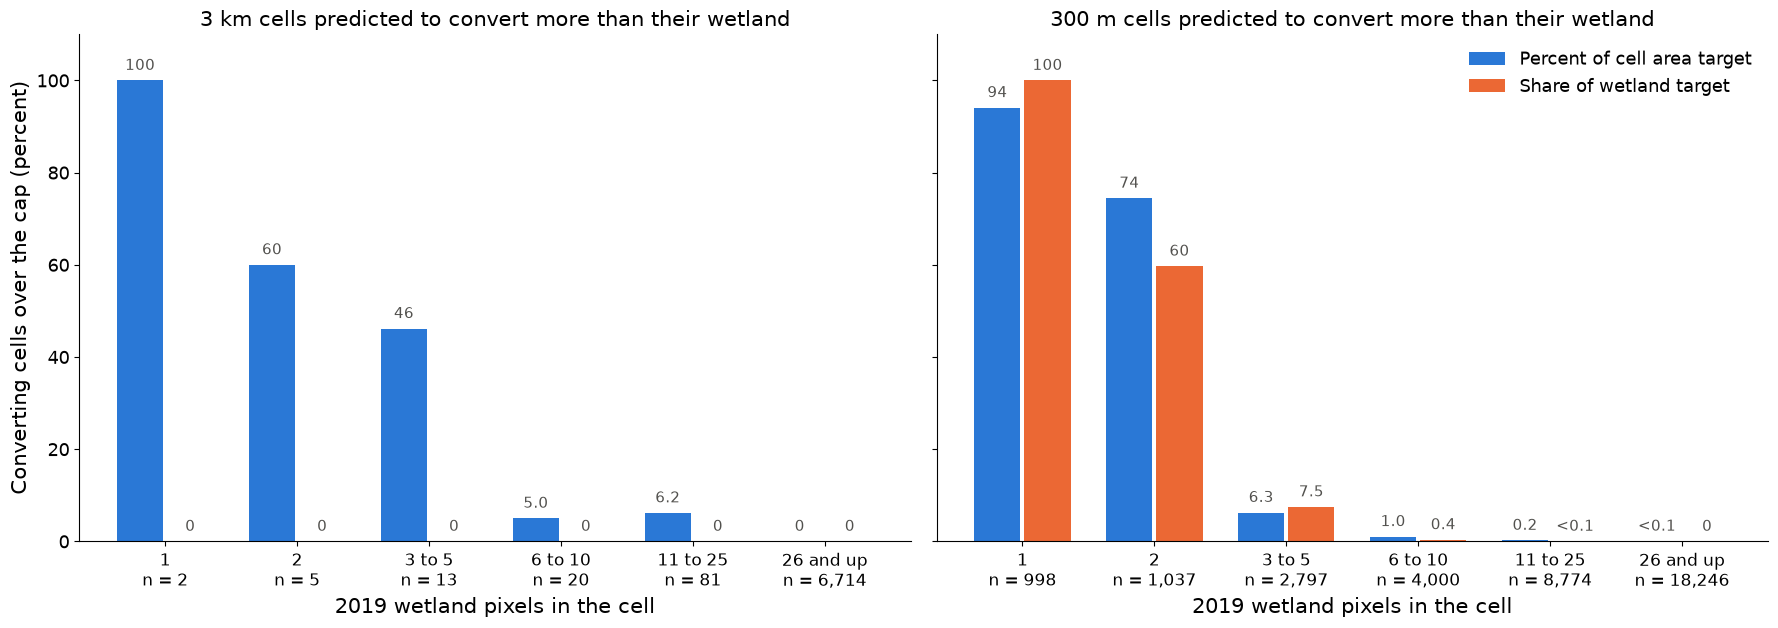

In [5]:
import matplotlib.pyplot as plt

FIG_DIR = ROOT / "results/figures/prediction_analysis"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 14, "axes.titlesize": 15, "axes.labelsize": 15,
                     "xtick.labelsize": 12, "ytick.labelsize": 13, "legend.fontsize": 13})

FIG_BINS = [0, 1, 2, 5, 10, 25, np.inf]
FIG_LABELS = ["1", "2", "3 to 5", "6 to 10", "11 to 25", "26 and up"]
# blue and orange are slots 1 and 2 of the reference categorical palette, safe under
# the common color vision deficiencies
TARGET_COLOR = {"area": "#2a78d6", "share": "#eb6834"}
TARGET_NAME = {"area": "Percent of cell area target", "share": "Share of wetland target"}
PANELS = {"3 km cells predicted to convert more than their wetland": {"area": "A", "share": "B"}, "300 m cells predicted to convert more than their wetland": {"area": "C", "share": "D"}}

def pct_over_by_bin(g):
    df = data[g]["val_preds"]
    b = pd.cut(df["n_wetland"], FIG_BINS, labels=FIG_LABELS)
    over = df["px_mean"] > df["n_wetland"]
    t = over.groupby(b, observed=False).agg(["size", "mean"])
    return t["size"], 100 * t["mean"]

fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), sharey=True)
x = np.arange(len(FIG_LABELS))
w = 0.38
for ax, (panel, groups) in zip(axes, PANELS.items()):
    for k, (target, g) in enumerate(groups.items()):
        n, pct = pct_over_by_bin(g)
        xs = x + (k - 0.5) * w
        ax.bar(xs, pct.values, w * 0.92, color=TARGET_COLOR[target], label=TARGET_NAME[target])
        for xi, v in zip(xs, pct.values):
            # values under 0.05 would print as 0.0 and read like an exact zero
            txt = "0" if v == 0 else ("<0.1" if v < 0.05 else f"{v:.1f}" if v < 10 else f"{v:.0f}")
            ax.text(xi, v + 1.5, txt, ha="center", va="bottom", fontsize=11, color="#52514e")
    # both targets in a panel use the same cells, so one count per bin
    ax.set_xticks(x, [f"{lab}\nn = {c:,}" for lab, c in zip(FIG_LABELS, n.values)])
    ax.set_title(panel)
    ax.set_xlabel("2019 wetland pixels in the cell")
    ax.set_ylim(0, 110)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
axes[0].set_ylabel("Converting cells over the cap (percent)")
axes[1].legend(frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig(FIG_DIR / "reg_over_wetland_cap_by_n_wetland.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

## Takeaways

* Yes, every group goes over at least sometimes before the clip, but how much depends a lot on cell size and target.
* B (3 km share) is basically clean: zero converting val cells over the cap, and only one cell in all of val after smearing.
* A (3 km area) has a few, all in cells with 20 or fewer wetland pixels out of a 10,000 pixel footprint. The area target never sees `n_wetland` in its definition, so on those cells a small absolute area error is a huge multiple of the wetland.
* C and D (300 m) go over on about 5% of converting val cells after smearing. Almost all of it is cells with 1 or 2 wetland pixels, where the true share is forced to be 100% (or 50%) and the log target sits right at the cap. MSE in log space pulls predictions toward 0 from both sides, and a smear of about 1.6 then pushes anything near 0 over.
* D raw `exp(pred)` goes over on only 0.3% of converting cells, so most of D's overshoot comes from the smear, not the network. C goes over 2.7% even before smearing, because the area target's ceiling changes cell to cell and the model has to learn it from `log1p(n_wetland)` and footprint.
* In aggregate the clip removes about 1% (C) and 0.6% (D) of predicted converted pixels on converting cells, so the pooled `pred_over_actual` numbers are only slightly affected. The per cell numbers on tiny cells are what's off.